# DSAI CROSS VALIDATION

In [63]:
from sklearn.datasets import load_breast_cancer, make_classification, load_wine
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import GridSearchCV


In [4]:
daten = load_breast_cancer(as_frame=True)

In [5]:
X, y = daten.data, daten.target

In [6]:
print(X.shape, y.shape)

(569, 30) (569,)


In [7]:
X

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [8]:
print(y.value_counts().rename({1: "gutartig",0:"bösartig"}))

target
gutartig    357
bösartig    212
Name: count, dtype: int64


## Das Problem der Lüge der Splits


In [9]:
accs= []
for seed in range(30):
    X_tr, X_test, y_tr,y_test = train_test_split(X, y, test_size=0.2,random_state=seed)
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    model.fit(X_tr, y_tr)
    model.fit(X_tr, y_tr)
    accs.append(accuracy_score(y_test, model.predict(X_test)))


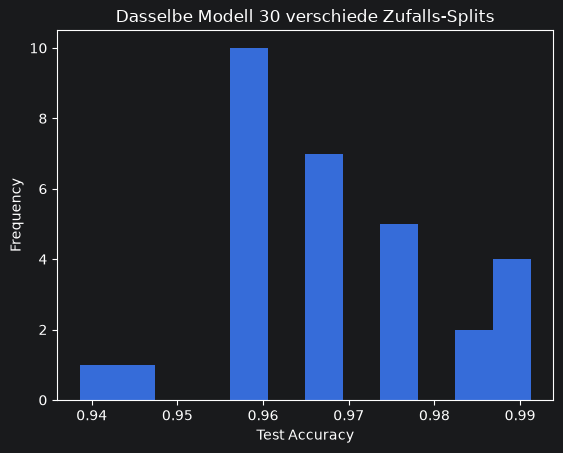

In [10]:

plt.hist(accs,bins=12)
plt.title('Dasselbe Modell 30 verschiede Zufalls-Splits')
plt.xlabel("Test Accuracy")
plt.ylabel("Frequency")
plt.show()

In [11]:
print(f"min:{min(accs)} max:{max(accs)} Spannweite:{max(accs)-min(accs)}")

min:0.9385964912280702 max:0.9912280701754386 Spannweite:0.05263157894736836


## Train / Validation / Test


In [12]:
X_rest, X_test, y_rest,y_test = train_test_split(X, y, test_size=0.2,random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_rest, y_rest, test_size=0.25,random_state=42)

print(X_tr.shape, y_tr.shape, y_val.shape,X_test.shape, y_test.shape)

(341, 30) (341,) (114,) (114, 30) (114,)


In [13]:
result = {}
for k in [1,3,5,7,9,15,25,51]:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_tr, y_tr)
    result[k] = accuracy_score(y_val, m.predict(X_val))


In [14]:
result

{1: 0.9649122807017544,
 3: 0.9824561403508771,
 5: 0.9824561403508771,
 7: 0.9736842105263158,
 9: 0.956140350877193,
 15: 0.9649122807017544,
 25: 0.9649122807017544,
 51: 0.9649122807017544}

In [15]:
best_k = max(result, key=result.get)
best_k

3

In [16]:
final = make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=best_k)).fit(X_tr, y_tr)
print(f"Test-Accenrcy: {accuracy_score(y_test,final.predict(X_test))}")

Test-Accenrcy: 0.9473684210526315


# K-Cross Validation


In [17]:
kf = KFold(n_splits=5,random_state=42,shuffle=True)
scores=[]
for i ,(train_index, validation_index) in enumerate(kf.split(X_rest)):
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    m.fit(X_rest.iloc[train_index], y_rest.iloc[train_index])
    s = accuracy_score(y_rest.iloc[validation_index], m.predict(X_rest.iloc[validation_index]))
    scores.append(s)
    print(f"Fold: {i+1}: train:{len(train_index)}, validation:{len(validation_index)}, acc: {s:.4f}")
print(f"\nCV-Accuracy: {np.mean(scores):.4f}+-{np.std(scores):.4f}")


Fold: 1: train:364, validation:91, acc: 0.9670
Fold: 2: train:364, validation:91, acc: 0.9890
Fold: 3: train:364, validation:91, acc: 0.9670
Fold: 4: train:364, validation:91, acc: 0.9341
Fold: 5: train:364, validation:91, acc: 0.9560

CV-Accuracy: 0.9626+-0.0179


In [18]:
modell= make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
scores = cross_val_score(modell,X_rest,y_rest,cv=kf,scoring='accuracy')
print(scores)

[0.96703297 0.98901099 0.96703297 0.93406593 0.95604396]


# Wenn Klassen ungeleich verteilt sind

In [40]:
X_imb, y_imb = make_classification(n_samples=500, n_features=10, weights=[0.98,0.02],random_state=0)
print(f"postivie Fälle: ",y_imb.sum())

postivie Fälle:  16


In [41]:
for name, splitter in [
    ("KFold", KFold(5, shuffle=True, random_state=3)),
    ("StratifiedKFold", StratifiedKFold(5, shuffle=True, random_state=3)),
]:
    print(name, "positive Fälle pro Validation Fold:")
    print([int(y_imb[val].sum()) for _, val in splitter.split(X_imb, y_imb)])

KFold positive Fälle pro Validation Fold:
[2, 5, 4, 2, 3]
StratifiedKFold positive Fälle pro Validation Fold:
[3, 3, 3, 3, 4]


## GridSearchCV - Hyperparameter-Suche mit eingebauter Cross Validation

In [43]:
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())


In [50]:
grid = GridSearchCV(pipe,param_grid={
    "kneighborsclassifier__n_neighbors":[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,25,51],
    "kneighborsclassifier__weights":["uniform","distance"],

}, cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42),scoring='accuracy',return_train_score=True)
grid.fit(X_rest, y_rest)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'kneighborsclassifier__n_neighbors': [1, 2, ...], 'kneighborsclassifier__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be avai

In [51]:
print("best parameters:", grid.best_params_)
print("best score:", grid.best_score_)

best parameters: {'kneighborsclassifier__n_neighbors': 8, 'kneighborsclassifier__weights': 'uniform'}
best score: 0.9692307692307691


In [52]:
res = pd.DataFrame(grid.cv_results_)

In [56]:
tab = res[['param_kneighborsclassifier__n_neighbors','param_kneighborsclassifier__weights','mean_train_score','mean_test_score','std_test_score','rank_test_score']]

In [57]:
tab.columns= ["k","weights","train","validation","sd","rank"]

In [60]:
print(tab.sort_values("rank").round(3).to_string(index=False))

 k  weights  train  validation    sd  rank
 8  uniform  0.974       0.969 0.013     1
 7 distance  1.000       0.967 0.012     2
 8 distance  1.000       0.967 0.007     2
 7  uniform  0.973       0.967 0.012     2
 1  uniform  1.000       0.965 0.011     5
 1 distance  1.000       0.965 0.011     5
 2 distance  1.000       0.965 0.011     5
 6 distance  1.000       0.965 0.011     5
 5  uniform  0.976       0.963 0.011     9
 6  uniform  0.976       0.963 0.011     9
 5 distance  1.000       0.963 0.011     9
12 distance  1.000       0.963 0.011     9
11  uniform  0.968       0.963 0.011     9
11 distance  1.000       0.963 0.011     9
10  uniform  0.974       0.963 0.015     9
10 distance  1.000       0.963 0.011     9
14  uniform  0.966       0.963 0.016     9
14 distance  1.000       0.963 0.016     9
13 distance  1.000       0.960 0.015    19
12  uniform  0.970       0.960 0.015    19
 4 distance  1.000       0.960 0.015    19
13  uniform  0.968       0.960 0.015    19
 3 distance

In [61]:
print("Test Accuracy:", grid.score(X_test, y_test))

Test Accuracy: 0.956140350877193


# Wein TestSatz

In [64]:
data = load_wine(as_frame=True)
x,y =data.data ,